# Chapter 14: Classification and Clustering with Encoder-Only Transformers!!!

In [1]:
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

In [2]:
owners = ['my', 'our', 'her', 'the neighbors']
animals = {'dog': 'barking', 'cat': 'meowing', 'bird': 'chirping', 'cow': 'mooing'}
adverbs = ['sometimes', 'always', 'usually', 'never']

held_out = {('my', 'dog'), ('our', 'cat'), ('her', 'bird'), ('the neighbors', 'cow')}
mask_token = '<MASK>'
pad_token = '<PAD>'

train_data = []
test_data = []

for owner in owners:
    for animal, sound in animals.items():
        for adverb in adverbs:
            sentence = f'{owner} {animal} is {adverb} {mask_token}'
            pair = [sentence, sound]

            if (owner, animal) in held_out:
                test_data.append(pair)
            else:
                train_data.append(pair)

words = sorted({word for sentence, sound in train_data + test_data for word in sentence.split() + [sound]})

words.insert(0, pad_token)

mask_token_id = words.index(mask_token)
pad_token_id = words.index(pad_token)
words_counts = len(words)
word_to_index_dictionary = {}

for word_index, word in enumerate(words):
    word_to_index_dictionary[word] = word_index

In [3]:
test_data

[['my dog is sometimes <MASK>', 'barking'],
 ['my dog is always <MASK>', 'barking'],
 ['my dog is usually <MASK>', 'barking'],
 ['my dog is never <MASK>', 'barking'],
 ['our cat is sometimes <MASK>', 'meowing'],
 ['our cat is always <MASK>', 'meowing'],
 ['our cat is usually <MASK>', 'meowing'],
 ['our cat is never <MASK>', 'meowing'],
 ['her bird is sometimes <MASK>', 'chirping'],
 ['her bird is always <MASK>', 'chirping'],
 ['her bird is usually <MASK>', 'chirping'],
 ['her bird is never <MASK>', 'chirping'],
 ['the neighbors cow is sometimes <MASK>', 'mooing'],
 ['the neighbors cow is always <MASK>', 'mooing'],
 ['the neighbors cow is usually <MASK>', 'mooing'],
 ['the neighbors cow is never <MASK>', 'mooing']]

In [4]:
def get_data_loader(data):
    X_raw = []
    y_raw = []

    for sentence_data, sound_data in data:
        X_raw.append(torch.tensor([word_to_index_dictionary[word] for word in sentence_data.split()]).int())
        y_raw.append(word_to_index_dictionary[sound_data])

    X_tensor = pad_sequence(X_raw, batch_first=True)
    y_tensor = torch.tensor(y_raw).int()

    tensor_data = TensorDataset(X_tensor, y_tensor)
    data_loader = DataLoader(tensor_data, shuffle=True)

    return data_loader

train_data_loader = get_data_loader(train_data)
test_data_loader = get_data_loader(test_data)

In [5]:
embedding_dim = 8
qkv_dim = 8

class EncDecNet(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.enc_embedding = nn.Embedding(num_embeddings=words_counts, embedding_dim=embedding_dim)
        self.enc_queries = nn.Linear(qkv_dim, qkv_dim)
        self.enc_keys = nn.Linear(qkv_dim, qkv_dim)
        self.enc_values = nn.Linear(qkv_dim, qkv_dim)
        self.enc_linear = nn.Linear(embedding_dim, words_counts)
    
    @staticmethod
    def get_positional_encoding(x_param):
        token_positions = torch.arange(len(x_param)).unsqueeze(dim = 1)
        dimension_indices = torch.arange(0, embedding_dim, 2)
        frequencies = 1 / (10000 ** (dimension_indices / embedding_dim))
    
        positional_encoding = torch.zeros(len(x_param), embedding_dim)
        positional_encoding[:, 0::2] = torch.sin(token_positions * frequencies)
        positional_encoding[:, 1::2] = torch.cos(token_positions * frequencies)
    
        return positional_encoding

    def get_encoded_values(self, x_param):
        word_embedding = self.enc_embedding(x_param[0])
        positional_encoding = self.get_positional_encoding(x_param[0])
        encoded_values = word_embedding + positional_encoding

        return encoded_values
        
    @staticmethod
    def get_attention(query_param, key_param, value_param):
        softmax_input = (torch.matmul(query_param, key_param.T)) / torch.sqrt(torch.tensor(qkv_dim))
        
        return torch.matmul(torch.softmax(softmax_input, dim=1), value_param)
    
    def get_enc_output(self, x_param):
        enc_encoded_values = self.get_encoded_values(x_param)
        enc_queries = self.enc_queries(enc_encoded_values)
        enc_keys = self.enc_keys(enc_encoded_values)
        enc_values = self.enc_values(enc_encoded_values)
        dec_attention = self.get_attention(enc_queries, enc_keys, enc_values)
        dec_output = dec_attention + enc_encoded_values
    
        return dec_output
        
    def forward(self, x_param, teacher_forcing=True):
        enc_output = self.get_enc_output(x_param)
        mask_token_index = torch.where(x_param[0] == mask_token_id)[0][0].item()
        enc_linear_output = self.enc_linear(enc_output[mask_token_index])
        
        if teacher_forcing:
            return enc_linear_output
        else:
            return torch.argmax(enc_linear_output).unsqueeze(dim=0).int()

In [6]:
enc_dec_net = EncDecNet()
optimizer = torch.optim.Adam(enc_dec_net.parameters())
loss_func = torch.nn.CrossEntropyLoss()
losses = []

enc_dec_net.train()

for epoch in range(100):
    for X, y in train_data_loader:
        X = X[:, X[0] != pad_token_id]
        
        y_pred = enc_dec_net(X)

        y_pred_target = y_pred
        y_target = y.squeeze().long()
        
        loss = loss_func(y_pred_target, y_target)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        losses.append(loss.detach().item())

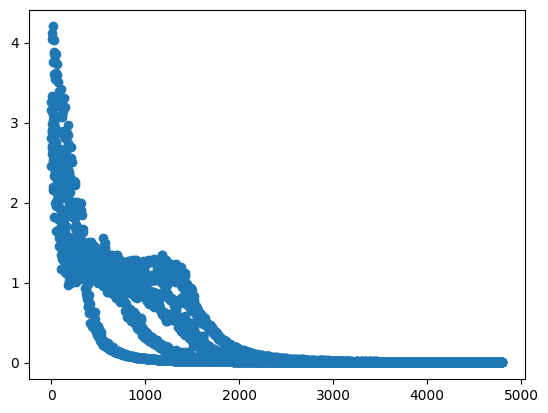

In [7]:
plt.scatter(range(len(losses)), losses)
plt.show()

In [8]:
def format_prediction(x_param, y_pred_param):
    sentence_words = [words[token_id] for token_id in x_param[0].tolist()]
    mask_token_index = sentence_words.index(mask_token)
    sentence_words[mask_token_index] = words[y_pred_param.item()]

    return ' '.join(sentence_words)

In [9]:
enc_dec_net.eval()

for X, y in test_data_loader:
    X = X[:, X[0] != pad_token_id]

    y_pred = enc_dec_net(X, teacher_forcing=False)

    y_pred_target = y_pred
    y_target = y

    print(y_pred_target)
    print(y_target)
    print(format_prediction(X, y_pred))
    print('---------------')

tensor([6], dtype=torch.int32)
tensor([6], dtype=torch.int32)
her bird is usually chirping
---------------
tensor([6], dtype=torch.int32)
tensor([6], dtype=torch.int32)
her bird is never chirping
---------------
tensor([12], dtype=torch.int32)
tensor([12], dtype=torch.int32)
the neighbors cow is never mooing
---------------
tensor([6], dtype=torch.int32)
tensor([6], dtype=torch.int32)
her bird is always chirping
---------------
tensor([11], dtype=torch.int32)
tensor([11], dtype=torch.int32)
our cat is usually meowing
---------------
tensor([3], dtype=torch.int32)
tensor([3], dtype=torch.int32)
my dog is usually barking
---------------
tensor([11], dtype=torch.int32)
tensor([11], dtype=torch.int32)
our cat is never meowing
---------------
tensor([3], dtype=torch.int32)
tensor([3], dtype=torch.int32)
my dog is always barking
---------------
tensor([3], dtype=torch.int32)
tensor([3], dtype=torch.int32)
my dog is never barking
---------------
tensor([12], dtype=torch.int32)
tensor([12], dt